# Dar_047 - Apollo subsurface thermal: depth, differences, flags and time

## Questions
- What temperatures and signed lower-minus-upper differences are supported for each actual deployed sensor?
- How do bridge corrections, bit flags, missing clocks, depth and archival sampling affect interpretation?
- How do UTC month, quarter, four-month term, half-year, year, two-year and calendar-season summaries compare?
- On common valid dates, how do shallow/deep distributions differ without inferring a causal insulation coefficient?
- Do original thermometer summaries agree with Dar_044, and what may inform Stage 4?

All 30 selected clean Apollo 15/17 tables are analysed. Sensor positions come from the provider's depth table, including above-surface instruments. Derived bridge elements use documented corrected differences when present. This is historical nonpolar context, not a polar equipment-temperature history or heat-flux measurement. Calendar seasons are labels only.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'darrel stuff/EDA').is_dir())
sys.path.insert(0,str(root/'darrel stuff/EDA/Moon/Stage3_Requirements'))
from stage3_hfe_eda import execute

## Execute the full study
Raw science and documentation are receipt/hash checked. Sample validation precedes this full run; the saved notebook executes the complete selected cohort.

In [2]:
folder,findings=execute(sample=False)
display(findings)

{
  "subject": "subsurface_thermal",
  "sample": false,
  "analysed_files": 30,
  "native_table_records": 520977,
  "undated_native_records": 131,
  "series": 100,
  "first_utc": "1971-07-31 00:00:00+00:00",
  "last_utc": "1977-09-30 00:00:00+00:00",
  "tables": {
    "daily_context": 83485,
    "sensor_metadata": 100,
    "native_field_statistics": 150,
    "flags_by_file": 510,
    "file_clock_lineage": 30,
    "merged_clock_support": 100,
    "difference_corrections": 26,
    "calendar_context": 8790,
    "matched_January_December_years": 400,
    "matched_depth_years": 16,
    "crosscheck_Dar044": 32545,
    "stage4_hfe_proposals": 5
  },
  "base_conclusion": "Depth, deployment, signed differences, archive sampling and missing/flagged periods matter. These historical nonpolar sensors cannot establish polar equipment temperature, heat flux, excavation benefit or a safe season.",
  "time_contract": "UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000

{'subject': 'subsurface_thermal',
 'sample': False,
 'analysed_files': 30,
 'native_table_records': 520977,
 'undated_native_records': 131,
 'series': 100,
 'first_utc': '1971-07-31 00:00:00+00:00',
 'last_utc': '1977-09-30 00:00:00+00:00',
 'tables': {'daily_context': 83485,
  'sensor_metadata': 100,
  'native_field_statistics': 150,
  'flags_by_file': 510,
  'file_clock_lineage': 30,
  'merged_clock_support': 100,
  'difference_corrections': 26,
  'calendar_context': 8790,
  'matched_January_December_years': 400,
  'matched_depth_years': 16,
  'crosscheck_Dar044': 32545,
  'stage4_hfe_proposals': 5},
 'base_conclusion': 'Depth, deployment, signed differences, archive sampling and missing/flagged periods matter. These historical nonpolar sensors cannot establish polar equipment temperature, heat flux, excavation benefit or a safe season.',
 'time_contract': 'UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000; four-month term=Jan-Apr/May-Aug/Sep-Dec; 

## Sensor position, lineage and quality
TREF is in the electronics box, not the soil. Positive/negative signed differences are retained. The mangled HTR field is not used to infer heater performance. Native statistics are per-file; derived daily summaries also screen cross-file clock ambiguity.

In [3]:
display(pd.read_csv(folder/'sensor_metadata.csv'))
display(pd.read_csv(folder/'file_clock_lineage.csv'))
display(pd.read_csv(folder/'difference_corrections.csv'))
display(pd.read_csv(folder/'flags_by_file.csv').groupby(['bit','meaning'],as_index=False).records.sum())

,series_id,mission,probe,file_number,field,depth_cm,position,unit,difference_basis,quality,scope
0,HFE_a15_p1f1_T,a15,p1,1,T,NaN,not a single deployed sensor depth,K,T,"strict flags==0, dated, finite; absolute tempe...",historical deployed Apollo sensor; not polar-s...
1,HFE_a15_p1f1_dT_selected,a15,p1,1,dT_selected,NaN,lower minus upper,K,provider dT_corr,"strict flags==0, dated, finite; absolute tempe...",historical deployed Apollo sensor; not polar-s...
2,HFE_a15_p1f1_upper_A,a15,p1,1,upper_A,35.0,35,K,provider dT_corr,"strict flags==0, dated, finite; absolute tempe...",historical deployed Apollo sensor; not polar-s...
3,HFE_a15_p1f1_lower_B,a15,p1,1,lower_B,84.0,84,K,provider dT_corr,"strict flags==0, dated, finite; absolute tempe...",historical deployed Apollo sensor; not polar-s...
4,HFE_a15_p1f1_gradient,a15,p1,1,gradient,NaN,bridge separation only; not heat flux,K/m,provider dT_corr,"strict flags==0, dated, finite; absolute tempe...",historical deployed Apollo sensor; not polar-s...
...,...,...,...,...,...,...,...,...,...,...,...
95,HFE_a17_p2f5_T,a17,p2,5,T,NaN,not a single deployed sensor depth,K,T,"strict flags==0, dated, finite; absolute tempe...",historical deployed Apollo sensor; not polar-s...
96,HFE_a17_p2f5_dT_selected,a17,p2,5,dT_selected,NaN,lower minus upper,K,provider clean dT (no correction field declared),"strict flags==0, dated, finite; absolute tempe...",historical deployed Apollo sensor; not polar-s...
97,HFE_a17_p2f5_upper_A,a17,p2,5,upper_A,196.0,196,K,provider clean dT (no correction field declared),"strict flags==0, dated, finite; absolute tempe...",historical deployed Apollo sensor; not polar-s...
98,HFE_a17_p2f5_lower_B,a17,p2,5,lower_B,224.0,224,K,provider clean dT (no correction field declared),"strict flags==0, dated, finite; absolute tempe...",historical deployed Apollo sensor; not polar-s...


,file,mission,probe,file_number,records,undated_records,ambiguous_or_missing_clock_records,nonpositive_adjacent_time_steps,median_positive_spacing_s,lineage,first_utc,last_utc,clock_contract
0,a15_1975p1f1.tab,a15,p1,1,17430,0,0,0,434.709,recovered 1975,1975-04-02 00:03:37.873000+00:00,1975-06-30 23:49:19.675000+00:00,provider mission epoch without leap seconds; n...
1,a15_1975p1f2.tab,a15,p1,2,17408,0,0,0,434.709,recovered 1975,1975-04-02 00:03:42.701000+00:00,1975-06-30 23:49:24.505000+00:00,provider mission epoch without leap seconds; n...
2,a15_1975p2f1.tab,a15,p2,1,17411,0,0,0,434.709,recovered 1975,1975-04-02 00:04:32.209000+00:00,1975-06-30 23:50:14.005000+00:00,provider mission epoch without leap seconds; n...
3,a15_1975p2f2.tab,a15,p2,2,17376,0,0,0,434.709,recovered 1975,1975-04-02 00:04:37.041000+00:00,1975-06-30 23:50:18.835000+00:00,provider mission epoch without leap seconds; n...
4,a15p1f1.tab,a15,p1,1,28931,0,0,0,3477.000,Lamont-NSSDC 1971-1974; archive downsampled,1971-08-04 05:22:58+00:00,1974-12-31 21:09:10+00:00,provider mission epoch without leap seconds; n...
5,a15p1f2.tab,a15,p1,2,29100,69,69,0,3477.000,Lamont-NSSDC 1971-1974; archive downsampled,1971-07-31 19:51:44+00:00,1974-12-31 21:07:20+00:00,provider mission epoch without leap seconds; n...
6,a15p1f3.tab,a15,p1,3,29844,0,2,1,3477.000,Lamont-NSSDC 1971-1974; archive downsampled,1971-07-31 19:47:59+00:00,1974-12-31 21:13:30+00:00,provider mission epoch without leap seconds; n...
7,a15p1f4.tab,a15,p1,4,613,0,0,0,172782.500,Lamont-NSSDC 1971-1974; archive downsampled,1971-08-02 14:09:53+00:00,1974-12-27 12:44:10+00:00,provider mission epoch without leap seconds; n...
8,a15p1f5.tab,a15,p1,5,614,0,0,0,172700.000,Lamont-NSSDC 1971-1974; archive downsampled,1971-08-02 14:19:55+00:00,1974-12-27 12:37:10+00:00,provider mission epoch without leap seconds; n...
9,a15p2f1.tab,a15,p2,1,28000,62,62,0,3478.000,Lamont-NSSDC 1971-1974; archive downsampled,1971-08-05 03:38:45+00:00,1974-12-31 21:10:00+00:00,provider mission epoch without leap seconds; n...


,file,selected_field,strict_dated_records,strict_corrected_different_records,maximum_absolute_correction_K,strict_negative_selected_difference_records
0,a15_1975p1f1.tab,provider clean dT (no correction field declared),17420,0,0.000000,8975
1,a15_1975p1f2.tab,provider clean dT (no correction field declared),17399,0,0.000000,0
2,a15_1975p2f1.tab,provider clean dT (no correction field declared),17411,0,0.000000,8271
3,a15_1975p2f2.tab,provider clean dT (no correction field declared),17363,0,0.000000,0
4,a15p1f1.tab,provider dT_corr,28733,12674,3.750000,12688
5,a15p1f2.tab,provider clean dT (no correction field declared),29006,0,0.000000,45
6,a15p1f4.tab,provider dT_corr,529,241,1.000000,245
7,a15p1f5.tab,provider clean dT (no correction field declared),610,0,0.000000,0
8,a15p2f1.tab,provider dT_corr,24525,12972,30.958000,12972
9,a15p2f2.tab,provider dT_corr,28037,157,6.557999,159


,bit,meaning,records
0,-2,unknown flag bits,0
1,-1,invalid/missing flag,0
2,0,strict zero flags,516331
3,1,missing data,321
4,2,ambiguous bitflip,254
5,4,outlier dT,326
6,8,outlier T,256
7,16,HTR placeholder,0
8,32,TREF outlier,28
9,64,TC1 outlier,61


## Depth and calendar support
Full calendar denominators retain missing periods and partial years. The archive changes from downsampled Lamont data to recovered data; record counts are not qualified elapsed coverage. Two-year windows are even-year pairs, not forecasts.

period_kind
calendar_season    1350
four_month_term    1030
half_year           680
month              3770
quarter            1300
two_year            260
year                400
Name: rows, dtype: int64

,mission,probe,year,matched_valid_days,upper_depth_cm,lower_depth_cm,upper_p95_p05_span_K,lower_p95_p05_span_K,median_lower_minus_upper_daily_K,interpretation
0,a15,p1,1971,150,35.0,139.0,6.087977,0.137529,2.206387,same valid UTC dates but different sensor time...
1,a15,p1,1972,366,35.0,139.0,5.666371,0.160355,0.726745,same valid UTC dates but different sensor time...
2,a15,p1,1973,365,35.0,139.0,5.694991,0.204390,0.670480,same valid UTC dates but different sensor time...
3,a15,p1,1974,365,35.0,139.0,5.696706,0.157166,0.538490,same valid UTC dates but different sensor time...
4,a15,p1,1975,90,35.0,139.0,5.347300,0.052775,0.177750,same valid UTC dates but different sensor time...
5,a15,p2,1971,79,-6.0,97.0,129.377214,0.562390,-60.366479,same valid UTC dates but different sensor time...
6,a15,p2,1972,344,-6.0,97.0,142.286783,0.199971,-31.554969,same valid UTC dates but different sensor time...
7,a15,p2,1973,365,-6.0,97.0,142.005172,0.251233,71.741479,same valid UTC dates but different sensor time...
8,a15,p2,1974,363,-6.0,97.0,142.161075,0.209018,60.327979,same valid UTC dates but different sensor time...
9,a15,p2,1975,90,-6.0,97.0,139.072525,0.148138,66.449125,same valid UTC dates but different sensor time...


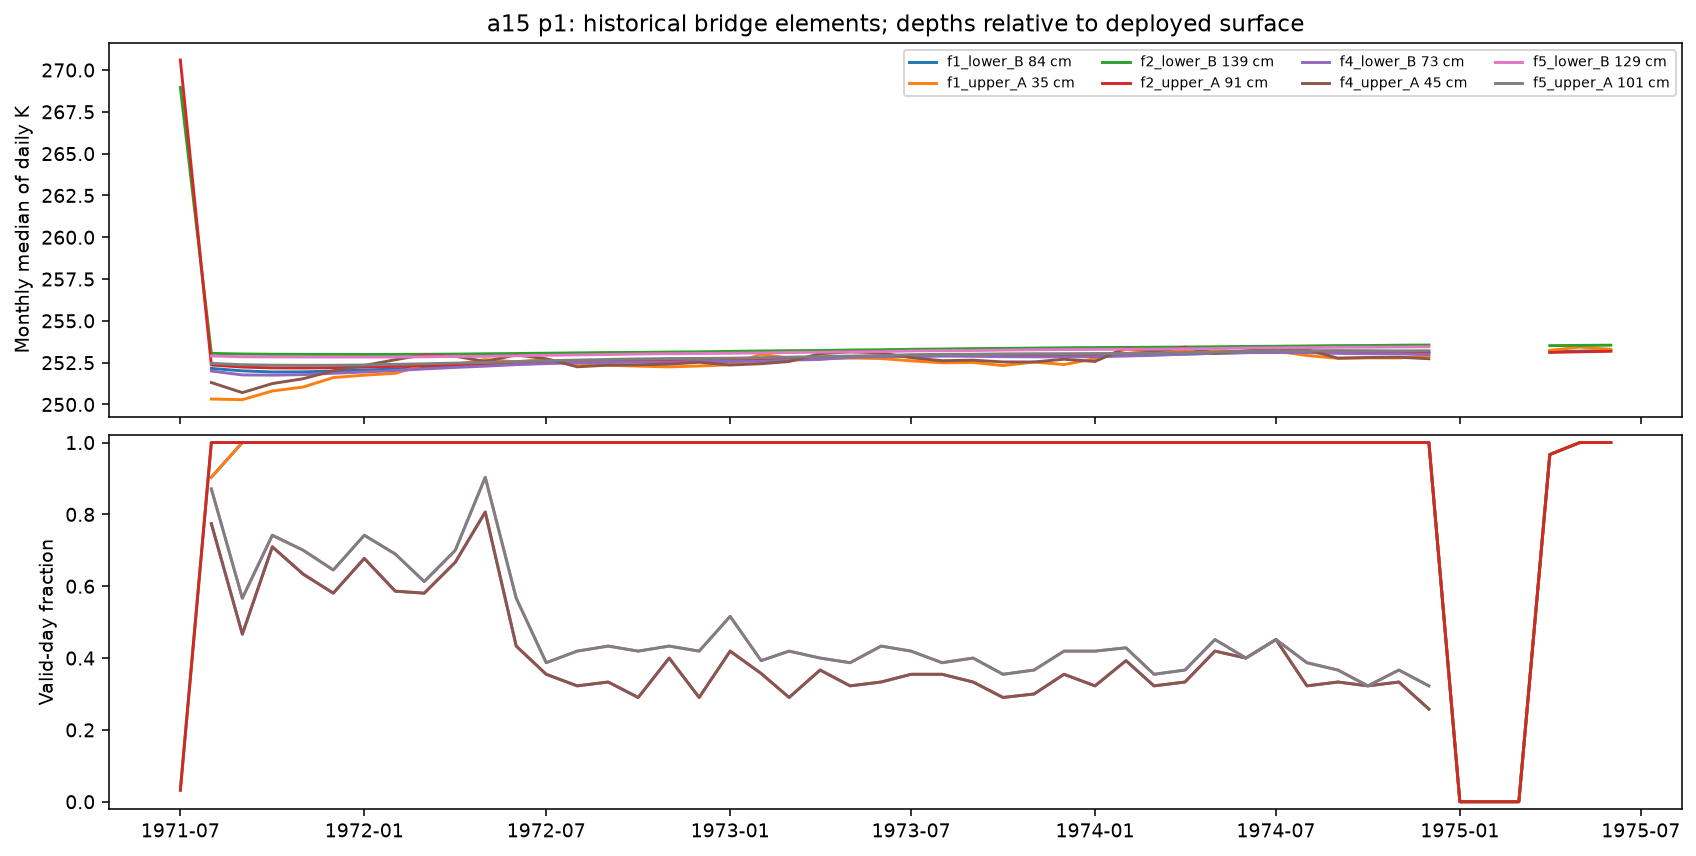

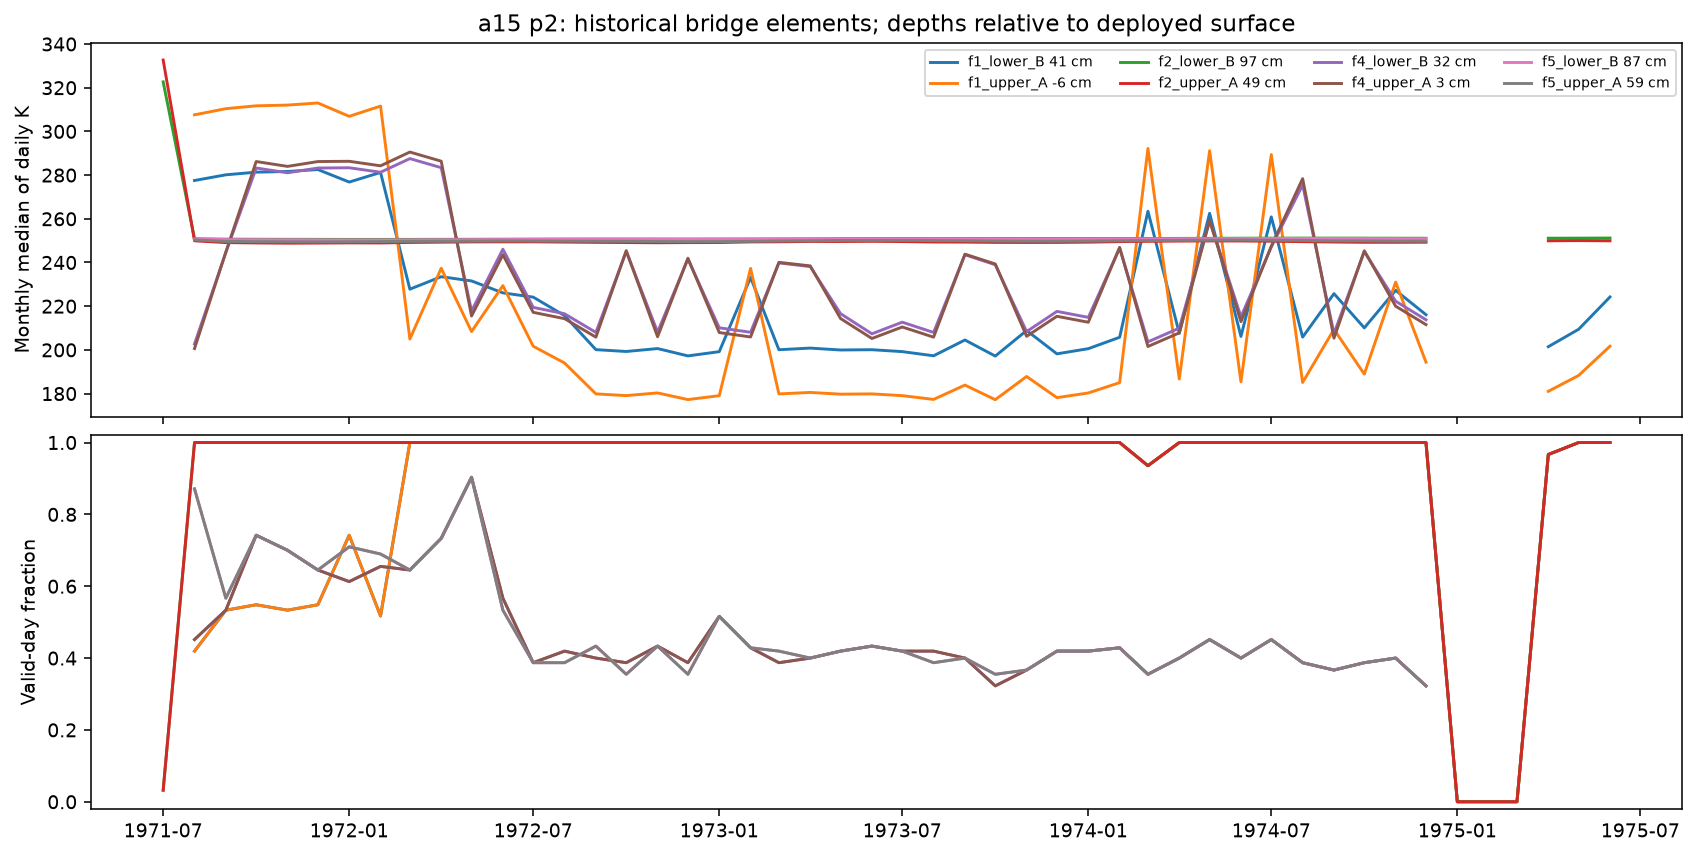

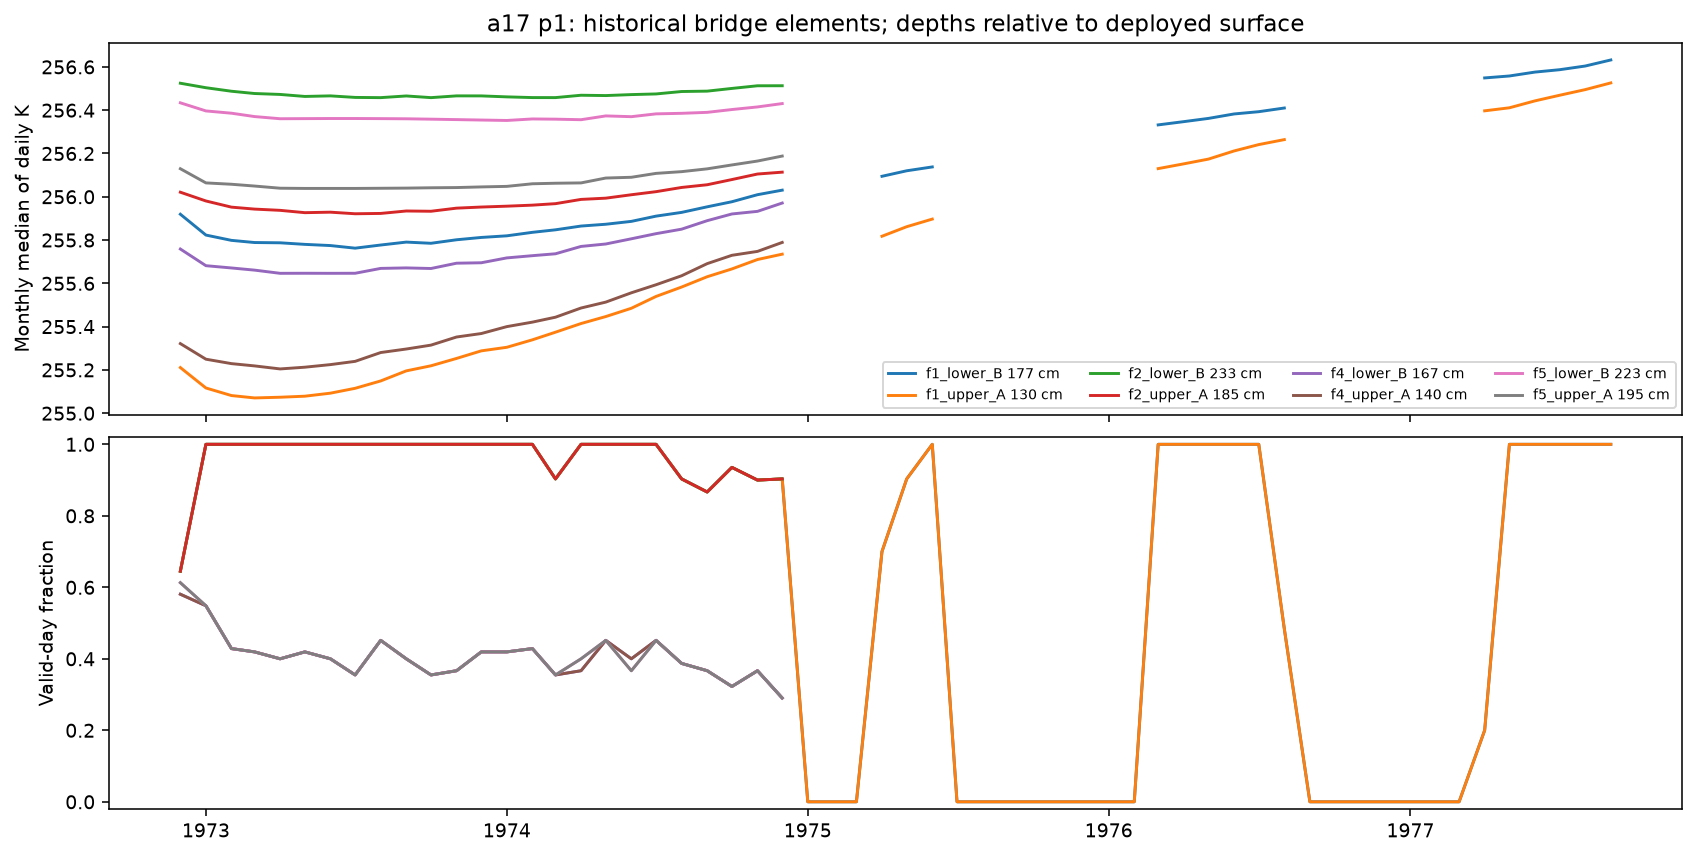

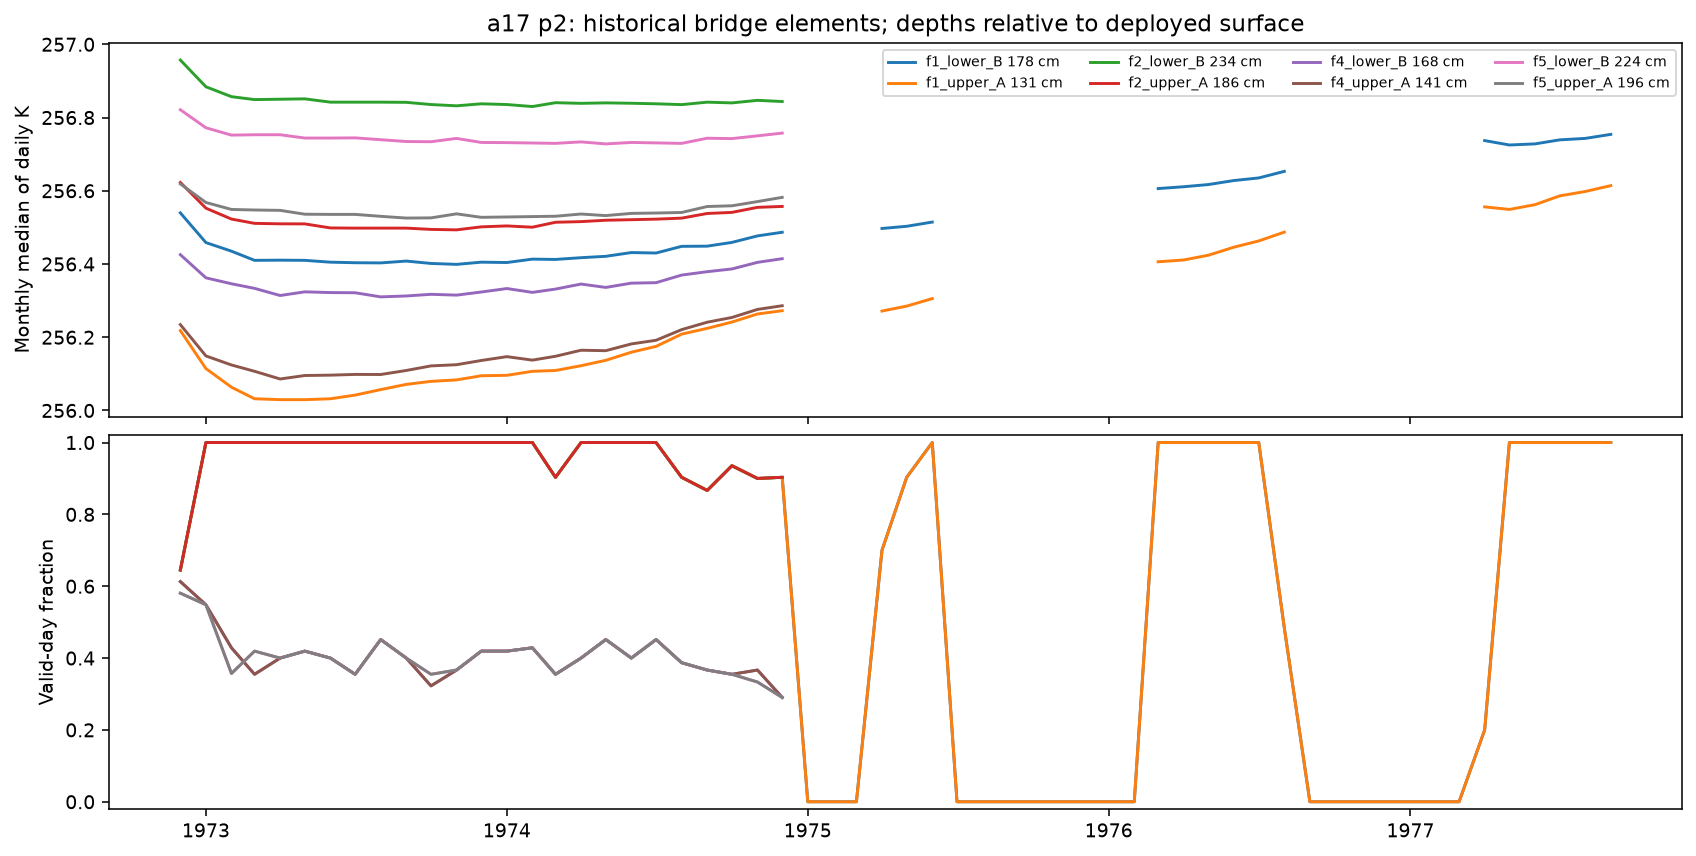

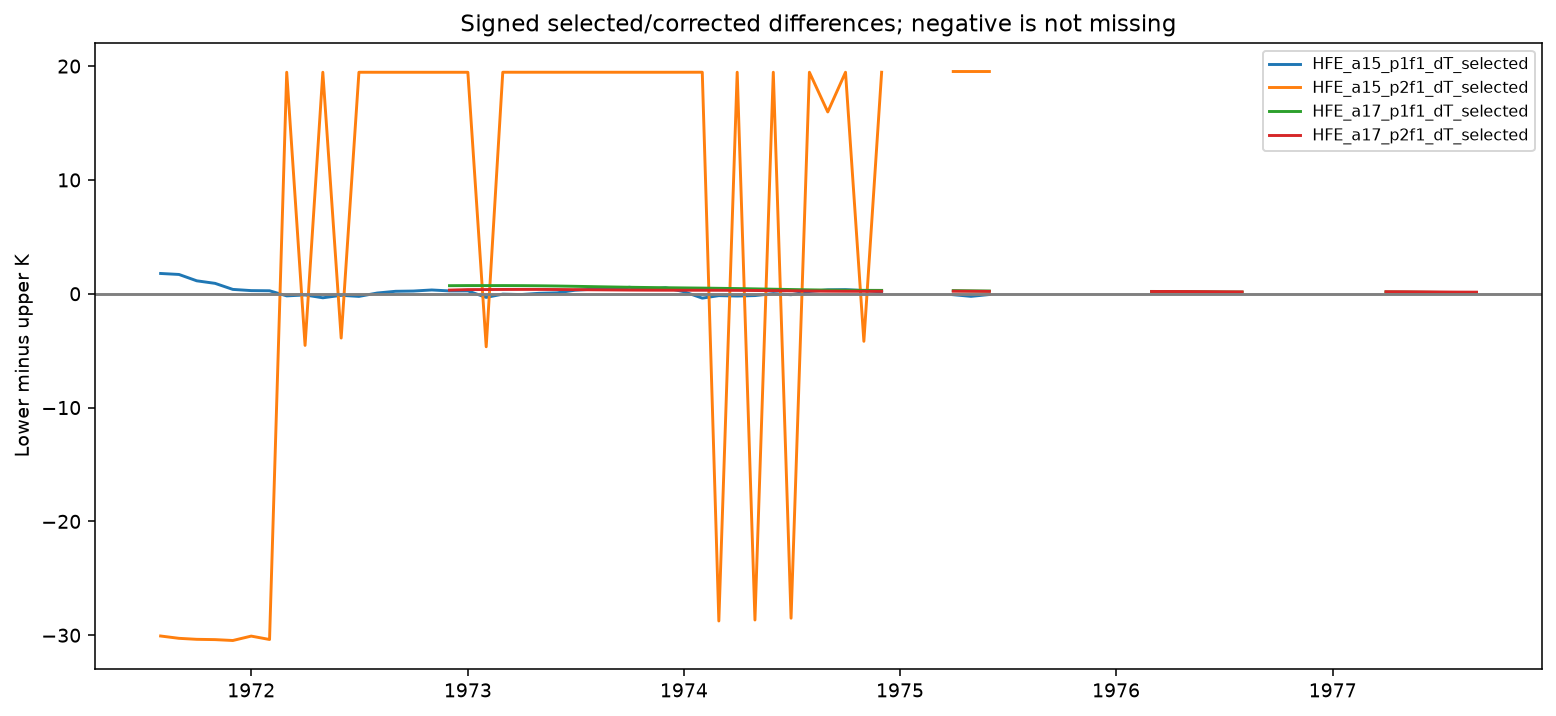

In [4]:
display(pd.read_csv(folder/'calendar_context.csv').groupby('period_kind').size().rename('rows'))
display(pd.read_csv(folder/'matched_depth_years.csv'))
for p in sorted(folder.glob('*depth_months.png')): display(Image(filename=str(p)))
display(Image(filename=str(folder/'signed_bridge_differences.png')))

## Cross-check existing EDA
Shared original thermometer values/support must match Dar_044. Corrected difference and individual-element analyses are additions, not replacements for its original summary contract.

In [5]:
checks=pd.read_csv(folder/'crosscheck_Dar044.csv')
display(checks.agg({'absolute_difference_K':'max','support_changed':'sum'}))
print('Matched original thermometer/day rows:',len(checks))

absolute_difference_K    5.684342e-14
support_changed          0.000000e+00
dtype: float64

Matched original thermometer/day rows: 32545


## Stage 4 proposal and base conclusion
Depth and thermal variability can inform what a local model must resolve. They do not prove burial benefit, modern equipment tolerance, heat flux or a safe arrival month. Missing local response, thermal properties and applicable requirements remain Unknown.

In [6]:
display(pd.read_csv(folder/'stage4_hfe_proposals.csv')[['id','classification','title','current_outcome','decision_logic']])
print(json.dumps(findings,indent=2))
print('Completed run:',folder)

,id,classification,title,current_outcome,decision_logic
0,HF-G01,evidence_guard,"Keep deployment, sensor depth and acquisition ...",Unknown,Do not assign equatorial Apollo temperatures o...
1,HF-G02,evidence_guard,Signed corrected differences and clock/flag su...,Unknown,Negative dT is meaningful; use documented corr...
2,HF-H01,conditional_hard_constraint,Applicable buried-system thermal envelope,Unknown,Failed if a qualified applicable component env...
3,HF-S01,conditional_soft_preference,Reduced qualified thermal-control burden,Unknown,"A deeper, quieter thermometer is not automatic..."
4,HF-G03,evidence_guard,No heat flux without applicable conductivity a...,Unknown,dT and dT/separation are difference/gradient c...


{
  "subject": "subsurface_thermal",
  "sample": false,
  "analysed_files": 30,
  "native_table_records": 520977,
  "undated_native_records": 131,
  "series": 100,
  "first_utc": "1971-07-31 00:00:00+00:00",
  "last_utc": "1977-09-30 00:00:00+00:00",
  "tables": {
    "daily_context": 83485,
    "sensor_metadata": 100,
    "native_field_statistics": 150,
    "flags_by_file": 510,
    "file_clock_lineage": 30,
    "merged_clock_support": 100,
    "difference_corrections": 26,
    "calendar_context": 8790,
    "matched_January_December_years": 400,
    "matched_depth_years": 16,
    "crosscheck_Dar044": 32545,
    "stage4_hfe_proposals": 5
  },
  "base_conclusion": "Depth, deployment, signed differences, archive sampling and missing/flagged periods matter. These historical nonpolar sensors cannot establish polar equipment temperature, heat flux, excavation benefit or a safe season.",
  "time_contract": "UTC; half-year=Jan-Jun/Jul-Dec; two-year=nonoverlapping even-year pairs anchored 2000